# Eksplorasi & Pemodelan Data Mining: Studi Kasus Prediksi Kualitas Anggur (Wine Quality)

**Penyusun:** Abelia Damayanti  
**NIM:** 2404010022  
**Program Studi:** D3 Statistika Terapan dan Komputasi UNNES  
**Dosen Pengampu:** Nur Achmey Selgi Harwanti, M.Stat  

---

### Pendekatan Metodologis
Pengerjaan Ujian Tengah Semester mata kuliah Data Mining ini bertujuan untuk memprediksi skala kualitas anggur (*Wine Quality*) berdasarkan 11 fitur prediktor kimiawi. Pemodelan dilakukan menggunakan pendekatan algoritma *ensemble tree* (*Extra Trees Regressor*) yang dipadukan dengan tahap *integer rounding* guna memodelkan hubungan non-linier serta gradasi skala kualitas secara tepat.

In [20]:
import warnings
warnings.filterwarnings('ignore')
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:
folder_path = '/content/drive/MyDrive/UTS_DataMining_Abelia Damayanti/'

train_df = pd.read_csv(folder_path + 'data_training.csv')
test_df = pd.read_csv(folder_path + 'data_testing.csv')

print("Ukuran Data Train:", train_df.shape)
print("Ukuran Data Test :", test_df.shape)
train_df.head()

Ukuran Data Train: (857, 13)
Ukuran Data Test : (286, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.3,0.740,0.08,1.7,0.094,10.0,45.0,0.99576,3.24,0.50,9.8,5,1366
1,8.1,0.575,0.22,2.1,0.077,12.0,65.0,0.99670,3.29,0.51,9.2,5,103
2,10.1,0.430,0.40,2.6,0.092,13.0,52.0,0.99834,3.22,0.64,10.0,7,942
3,12.9,0.500,0.55,2.8,0.072,7.0,24.0,1.00012,3.09,0.68,10.9,6,811
4,8.4,0.360,0.32,2.2,0.081,32.0,79.0,0.99640,3.30,0.72,11.0,6,918


### 1. Exploratory Data Analysis (EDA): Distribusi Kelas Target (`quality`)

Tahap eksplorasi awal dilakukan untuk mengamati sebaran nilai pada variabel target `quality` dalam data pelatihan.

Berdasarkan pengamatan, mayoritas sampel data terkonsentrasi pada skor kualitas 5 dan 6, sedangkan nilai kualitas ekstrem (3, 4, 7, dan 8) memiliki jumlah sampel yang relatif sedikit (*imbalanced target distribution*).

Temuan ini menjadi dasar pertimbangan untuk mengimplementasikan skema *Stratified K-Fold Cross-Validation* agar proporsi kelas pada setiap *fold* tetap terepresentasi secara seimbang.

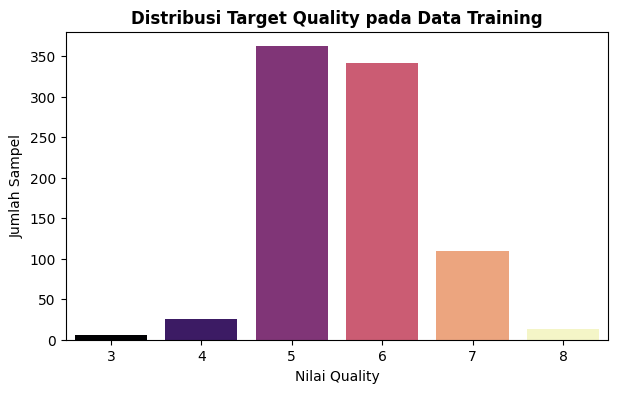

In [23]:
plt.figure(figsize=(7, 4))
sns.countplot(x='quality', data=train_df, hue='quality', palette='magma', legend=False)
plt.title('Distribusi Target Quality pada Data Training', fontsize=12, fontweight='bold')
plt.xlabel('Nilai Quality')
plt.ylabel('Jumlah Sampel')
plt.show()

### 2. Pemodelan & Validasi (*Extra Trees Regressor* & 5-Fold Stratified CV)

Algoritma **Extra Trees Regressor** (`n_estimators=1000`, `max_depth=20`) dipilih sebagai model utama karena mekanismenya dalam melakukan pemisahan *node* secara acak (*randomized splits*), yang efektif dalam mereduksi varians serta mencegah *overfitting* pada data tabular.

Nilai prediksi kontinu dari model regresi selanjutnya dibulatkan (*integer rounding*) ke skala bulat terdekat. Evaluasi performa diuji menggunakan *5-Fold Stratified Cross-Validation* untuk mengukur konsistensi akurasi model pada setiap lipatan data.

In [14]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

X = train_df.drop(columns=['quality', 'Id'])
y = train_df['quality']
X_test = test_df.drop(columns=['Id'])
test_id = test_df['Id']

model = ExtraTreesRegressor(n_estimators=1000, max_depth=20, random_state=42)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = []

for train_idx, val_idx in cv.split(X, y):
    X_tr, X_va = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_va = y.iloc[train_idx], y.iloc[val_idx]

    model.fit(X_tr, y_tr)
    preds = np.round(model.predict(X_va)).astype(int)
    cv_scores.append(accuracy_score(y_va, preds))

print(f"Rata-rata Akurasi Validasi Model: {np.mean(cv_scores)*100:.2f}%")

Rata-rata Akurasi Validasi Model: 66.75%


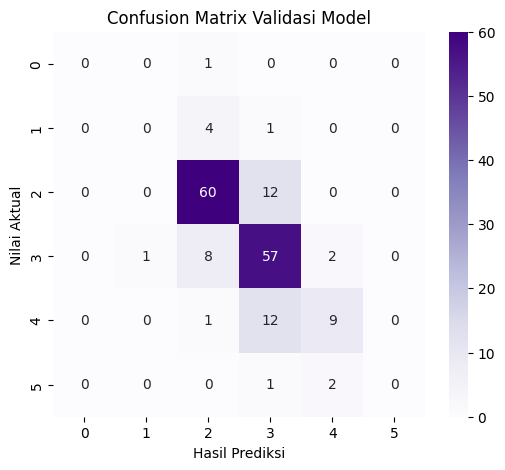

In [15]:
from sklearn.metrics import confusion_matrix

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_va, preds), annot=True, fmt='d', cmap='Purples')
plt.title('Confusion Matrix Validasi Model')
plt.xlabel('Hasil Prediksi')
plt.ylabel('Nilai Aktual')
plt.show()

### 3. Prediksi Data Pengujian (*Testing*) & Export Deliverables

Setelah mengonfirmasi stabilitas performa pada tahap validasi, model dilatih kembali (*retrain*) menggunakan seluruh dataset pelatihan untuk memaksimalkan penyerapan pola data.

Model akhir selanjutnya digunakan untuk memprediksi 286 sampel pada file `data_testing.csv`. Hasil prediksi disimpan ke dalam file `hasilprediksi_022.csv` dengan struktur 2 kolom (`Id` dan `Quality`) sesuai dengan petunjuk pengerjaan UTS.

In [16]:
X_test = test_df.drop(columns=['Id'])
test_id = test_df['Id']

In [17]:
model.fit(X, y)

final_predictions = np.round(model.predict(X_test)).astype(int)

submission = pd.DataFrame({
    'Id': test_id,
    'Quality': final_predictions
})

output_name = folder_path + 'hasilprediksi_022.csv'

submission.to_csv(output_name, index=False)

print(f"File berhasil dibuat dan disimpan di Drive: hasilprediksi_022.csv")
submission.head()

File berhasil dibuat dan disimpan di Drive: hasilprediksi_022.csv


,Id,Quality
0,222,5
1,1514,6
2,417,5
3,754,5
4,516,6
